# Example: plane-wave window of the LRG autocorrelation (RIC + AMR)

This example computes the low-$k$ part of the forward-model window as a deterministic integral over wavevectors (`desiwinds.planewave`), with no realizations to average over and down to $k$ below the fundamental mode of any mesh.

The randoms are split into two disjoint halves, each used as both data and randoms. The cross-response of the two halves has no self-pair term. Each half gets its own RIC and AMR arguments. The responses to single plane waves at quadrature nodes are then combined into window columns.

This notebook is meant to run on a shared GPU node at NERSC (one GPU). One GPU has a quarter of the memory of the 4-GPU node used in production, so the output mesh is smaller than in production (256 instead of 448), with the same `output_kmax`. Settings marked "production" are those of the DR2 QSO runs (one 4×A100 node).

The first chunk of nodes includes the compilation time.

In [1]:
import sys
sys.path.insert(0, "/global/homes/d/dchebat/window/desiwinds/src/")
import desiwinds

In [2]:
import itertools
import os
from pathlib import Path

os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.85"

import healpy as hp
import jax
jax.config.update("jax_enable_x64", True)  # as in production: effects and their derivatives in float64; meshes painted in float32 below
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from jaxpower import BinMesh2SpectrumPoles, FKPField, compute_fkp2_normalization, get_mesh_attrs
from tqdm import tqdm

from desiwinds.convenience import fiducial_planck_2018, get_randoms, get_sysmap, split_into_halves
from desiwinds.planewave import get_planewave_nodes, get_planewave_responses, get_planewave_window, prepare_halves_effects

## Parameters
Adjust data paths and redshift ranges to match your environment.

In [3]:
n_randoms = 1

boxsize = 8000.0
cellsize = 40.0

tracer = "LRG"
z_range = (0.4, 1.1)

pk_regions = ["SGC", "NGC"]
photo_regions = ["N", "S"]  # Photometric regions for LRG
z_ranges = [(0.4, 0.5), (0.5, 0.6), (0.6, 0.7), (0.7, 0.8), (0.8, 0.9), (0.9, 1.0), (1.0, 1.1)]  # Redshift ranges for the angular systematics regression

regression_maps = [
    "STARDENS",
    "PSFSIZE_G",
    "PSFSIZE_R",
    "PSFSIZE_Z",
    "GALDEPTH_G",
    "GALDEPTH_R",
    "GALDEPTH_Z",
    "HI",
    "PSFDEPTH_W1",
    "EBV_DIFF_GR",
    "EBV_DIFF_RZ",
]  # LRG templates

randoms_basedir = Path("/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/fNL")
templates_dir = Path("/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/hpmaps/")
ebvdir = Path("/dvs_ro/cfs/cdirs/desicollab/users/rongpu/data/ebv/desi_stars_y3/v0.1/final_maps/lss/")

# Plane-wave options
output_meshsize = 256  # mesh of the painted tangents (production: 448 on 4 GPUs; one GPU has a quarter of the memory)
output_kmax = 0.03  # keep observed bins with upper edge <= output_kmax (required under jit)
batch_size = 4  # nodes evaluated at once
chunk = 96  # nodes per jitted call, a multiple of batch_size: every call has the same shape, so one compilation

## Load randoms and split them into halves

### Imaging templates

In [4]:
sysmaps_south = get_sysmap(
    map_path=Path(
        templates_dir / f"{tracer}_mapprops_healpix_nested_nside256_S.fits"
    ),
    region="S",
    ebv_path=ebvdir / "desi_ebv_lss_256.fits",
)
sysmaps_south.keep_columns(regression_maps)
sysmaps_south = np.lib.recfunctions.structured_to_unstructured(
    sysmaps_south.as_array()
).astype(float)

sysmaps_north = get_sysmap(
    map_path=Path(
        templates_dir / f"{tracer}_mapprops_healpix_nested_nside256_N.fits"
    ),
    region="N",
    ebv_path=ebvdir / "desi_ebv_lss_256.fits",
)
sysmaps_north.keep_columns(regression_maps)
sysmaps_north = np.lib.recfunctions.structured_to_unstructured(
    sysmaps_north.as_array()
).astype(float)

sysmaps = np.where(sysmaps_south == 0.0, sysmaps_north, sysmaps_south)
sysmapsnan = np.where(sysmaps == 0.0, np.nan, sysmaps)

sysmaps -= np.nanmean(sysmapsnan, axis=0)
sysmaps /= np.nanstd(sysmapsnan, axis=0)

del sysmaps_south, sysmaps_north, sysmapsnan

### Randoms catalogs

Each cap is split into two disjoint halves A and B, each an FKP field whose data and randoms are the same particles. The normalization is computed on A as data and B as randoms, held fixed, as in `autocorr_forward_example.ipynb`; in production, take it from the measured spectrum.

In [5]:
halves = []  # one (A, B) pair per cap
fkp_norms = []

for pk_region in pk_regions:
    position, [weight, weight_FKP], redshift = get_randoms(
        n_randoms,
        pk_region,
        z_range,
        tracer,
        "FKP",
        basedir=randoms_basedir,
        return_redshift=True,
    )

    template_values = sysmaps[hp.vec2pix(256, *position.T, nest=True)]

    # Create mesh attributes
    mattrs = get_mesh_attrs(position, cellsize=cellsize, boxsize=boxsize, check=True)

    # Two disjoint halves, each used as both data and randoms
    half_a, half_b = split_into_halves(
        position,
        weight,
        extra={"Z": redshift, "weight_FKP": weight_FKP, "template_values": template_values},
        split_seed=123,
        mattrs=mattrs,
        exchange=True,
        backend="jax",
    )
    halves.append((half_a, half_b))

    # Normalization (held fixed)
    binner = BinMesh2SpectrumPoles(mattrs=mattrs, edges={"min": 0.002, "step": 0.002}, ells=(0, 2, 4))
    fkp_norm = compute_fkp2_normalization(FKPField(data=half_a.data, randoms=half_b.data, attrs=mattrs), bin=binner, cellsize=20.0)
    fkp_norms.append(fkp_norm)

    del position, weight, weight_FKP, redshift, template_values, half_a, half_b
del sysmaps

## Build RIC and AMR arguments of each half

The effects are prepared jointly over the two caps, on each half with its particles as both data and randoms.

In [6]:
ric_args, amr_args, _ = prepare_halves_effects(
    halves,
    ric_kwargs=dict(regions=photo_regions, n_bins=1000, apply_to="randoms"),
    amr_kwargs=dict(regions_zranges=list(itertools.product(photo_regions, z_ranges)), apply_to="randoms"),
)

jax.block_until_ready((ric_args, amr_args));

In [7]:
# The templates and redshifts are no longer needed: drop them to save memory (keep weight_FKP, used at estimation time)
def drop_extra(fkp):
    particles = fkp.data.clone(extra={k: fkp.data.extra[k] for k in fkp.data.extra.keys() - {"template_values", "Z"}})
    return FKPField(particles, particles, attrs=fkp.attrs)


halves = [tuple(drop_extra(half) for half in pair) for pair in halves]

## Quadrature nodes

Gauss-Legendre in $\ln k$ times Fibonacci directions on a hemisphere, per segment of $k$. These segments cover the first theory bins below $k \approx 2 \times 10^{-3}$, where the forward model has few or no mesh modes (here $k_f = 2\pi / 8000 \approx 7.9 \times 10^{-4}$). The production node grids (`desiwinds_validation/planewave/nodes.py`) use more directions (48 to 128 per magnitude); 64 directions are converged for the observed monopole and quadrupole on the test survey.

In [8]:
segments = [  # (k_edges, magnitudes per segment, directions)
    (np.geomspace(3e-5, 5e-4, 4), 2, 32),  # tail: the integrand goes as k with the integral constraints
    (np.arange(5e-4, 2e-3 + 1e-9, 2.5e-4), 2, 48),
]
kvec, weights = map(np.concatenate, zip(*[get_planewave_nodes(edges, n_k=n_k, n_directions=n_dir) for edges, n_k, n_dir in segments]))
theory_edges = np.unique(np.concatenate([edges for edges, _, _ in segments]))  # edges of the spike columns below
print(f"{len(kvec)} nodes, {int(np.ceil(len(kvec) / chunk))} chunks of {chunk}")

768 nodes, 8 chunks of 96


## Plane-wave responses

The call is jitted once: the options are static, the binner is a constant (it is rebuilt on the output mesh from its edges, which is why `output_kmax` is required), and every chunk of nodes has the same shape. The halves of a cap are passed as one pair (A, B) and crossed; `data_is_randoms=True` paints each half once.

In [9]:
static = ("estimator_weights", "data_is_randoms", "mesh_dtype", "batch_size", "paint_kwargs", "output_meshsize", "output_kmax")


def run(halves, kvec, ric_args, amr_args, fkp_norms, **options):
    options["paint_kwargs"] = dict(options["paint_kwargs"])  # a tuple of pairs to be hashable as a static argument
    return get_planewave_responses(
        *halves,
        kvec=kvec,
        ric_args=ric_args,
        amr_args=amr_args,
        data_regions=tuple(args.data_regions for args in ric_args),
        randoms_regions=tuple(args.randoms_regions for args in ric_args),
        binner=binner,
        fkp_norms=fkp_norms,
        **options,
    )


jrun = jax.jit(run, static_argnames=static)
options = dict(
    estimator_weights="weight_FKP",
    data_is_randoms=True,
    mesh_dtype="float32",
    batch_size=batch_size,
    paint_kwargs=(("resampler", "cic"), ("interlacing", 0), ("compensate", True)),  # ~3x cheaper than the FM's TSC, interlaced 3, well below the Nyquist frequency
    output_meshsize=output_meshsize,
    output_kmax=output_kmax,
)

In [10]:
responses = []
for start in tqdm(range(0, len(kvec), chunk), desc="Plane-wave responses"):
    kv = kvec[start : start + chunk]
    n = len(kv)
    if n < chunk:  # pad the last chunk: same shape, no recompilation
        kv = np.concatenate([kv, np.repeat(kv[-1:], chunk - n, axis=0)])
    out = jax.block_until_ready(jrun(halves, kv, ric_args, amr_args, fkp_norms, **options))
    responses.append(np.asarray(out)[:n])
responses = np.concatenate(responses)  # (n_nodes, n_caps, 3, n_observed): R00, R02, R22 summed over +-k
assert np.isfinite(responses).all()
print(responses.shape)

Plane-wave responses:   0%|          | 0/8 [00:00<?, ?it/s]/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/site-packages/jax/_src/ops/scatter.py:104: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(
E1126 01:00:54.432017  143840 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E1126 01:00:54.591412  143840 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
Plane-wave responses: 100%|██████████| 8/8 [20:40<00:00, 155.02s/it]

(768, 2, 3, 42)


## Window columns

Spike columns: the response of the observed multipoles to the theory monopole set to 1 in one bin of `theory_edges` (and 0 elsewhere). Any other column (a basis vector, a theory) is a weighted sum of the same node responses.

In [11]:
n_observed = responses.shape[-1] // 3  # observed bins per multipole (ells 0, 2, 4)
k_observed = np.mean(np.asarray(binner.edges)[:n_observed], axis=-1)


def spike_shapes(k):
    # (n_columns, 3, len(k)): P0 = 1 in one theory bin, P2 = P4 = 0
    inbin = (k >= theory_edges[:-1, None]) & (k < theory_edges[1:, None])
    shapes = np.zeros((len(theory_edges) - 1, 3, len(k)))
    shapes[:, 0] = inbin
    return shapes


window = np.asarray(get_planewave_window(responses, weights, kvec, spike_shapes))  # (n_caps, n_observed * 3, n_columns)
print(window.shape)

(2, 42, 9)


Text(0.5, 0.98, 'Plane-wave window columns (theory monopole spikes)')

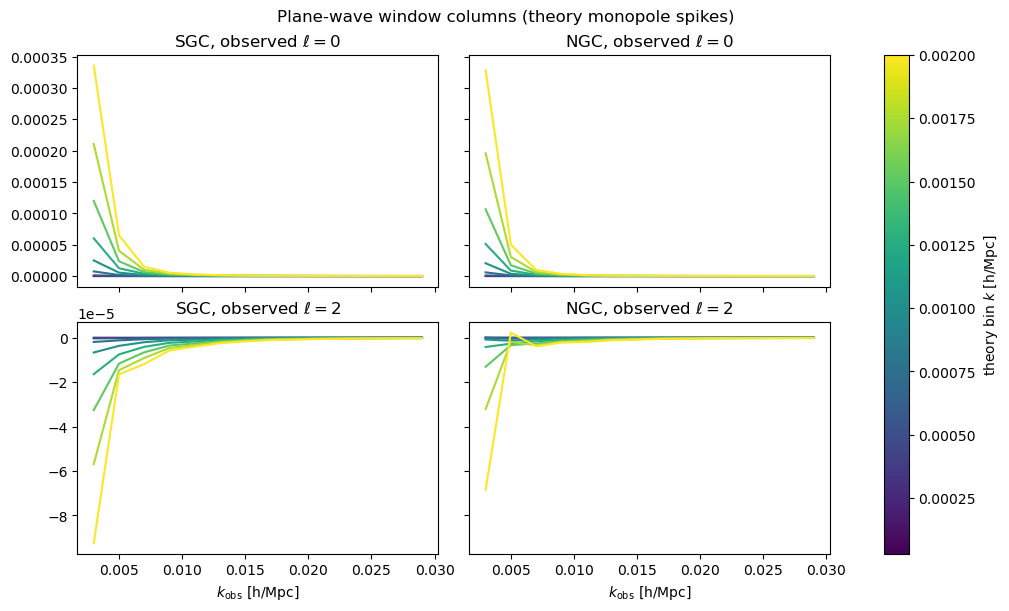

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey="row", layout="constrained")
colors = plt.cm.viridis(np.linspace(0, 1, window.shape[-1]))
for icap, cap in enumerate(pk_regions):
    for iell, ell in enumerate([0, 2]):
        ax = axes[iell, icap]
        for icol, color in enumerate(colors):
            ax.plot(k_observed, window[icap, iell * n_observed : (iell + 1) * n_observed, icol], color=color)
        ax.set_title(f"{cap}, observed $\\ell = {ell}$")
for ax in axes[-1]:
    ax.set_xlabel(r"$k_\mathrm{obs}$ [h/Mpc]")
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(theory_edges[0], theory_edges[-1]))
fig.colorbar(sm, ax=axes, label=r"theory bin $k$ [h/Mpc]")
fig.suptitle("Plane-wave window columns (theory monopole spikes)")

## Contribution of $k < 2 \times 10^{-3}$ to the observed spectrum

With the fiducial theory as the only column, restricted to the scales covered by the nodes, the window gives how much these scales contribute to the observed multipoles.

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuEngine cannot cope with massive neutrinos
  warnings.warn(


Text(0.5, 0.98, 'Contribution of theory scales $k \\in [3e-05, 2e-03]$')

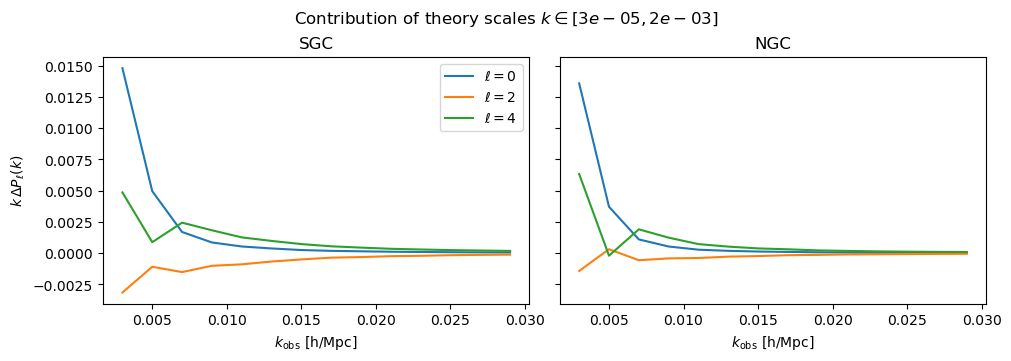

In [13]:
k_theory_edges = np.arange(0.0, 0.01 + 1e-9, 1e-5)
theory = fiducial_planck_2018(k_theory_edges)
k_theory = theory.get(0).coords("k")


def theory_shapes(k):
    # (1, 3, len(k)): the fiducial P0, P2, P4 below theory_edges[-1], 0 above
    inrange = (k >= theory_edges[0]) & (k < theory_edges[-1])
    return np.array([[np.interp(k, k_theory, theory.get(ell).value()) * inrange for ell in (0, 2, 4)]])


contribution = np.asarray(get_planewave_window(responses, weights, kvec, theory_shapes))[..., 0]  # (n_caps, n_observed * 3)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout="constrained")
for icap, (ax, cap) in enumerate(zip(axes, pk_regions, strict=True)):
    for iell, ell in enumerate([0, 2, 4]):
        ax.plot(k_observed, k_observed * contribution[icap, iell * n_observed : (iell + 1) * n_observed], label=f"$\\ell = {ell}$")
    ax.set_title(cap)
    ax.set_xlabel(r"$k_\mathrm{obs}$ [h/Mpc]")
axes[0].set_ylabel(r"$k \, \Delta P_\ell(k)$")
axes[0].legend()
fig.suptitle(rf"Contribution of theory scales $k \in [{theory_edges[0]:.0e}, {theory_edges[-1]:.0e}]$")